In [1]:
import numpy as np
import matplotlib.pyplot as plt

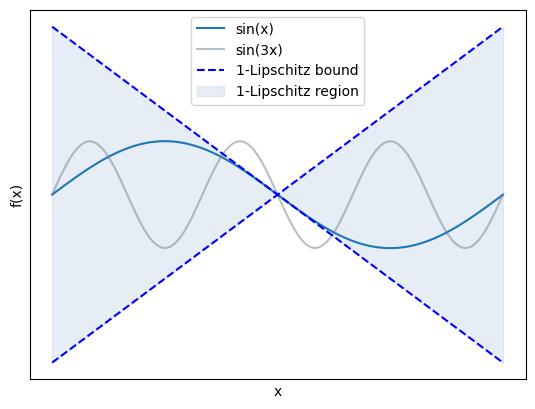

In [4]:
domain = np.linspace(0, 2 * np.pi, 100)

L = 1
eval_point_1 = np.pi
eval_point_2 = 3*np.pi / 2


f = np.sin(domain)
f_break = np.sin(3*domain)
bound1_L1 = L * (domain - eval_point_1) + np.sin(eval_point_1)
bound2_L1 = -L * (domain - eval_point_1) + np.sin(eval_point_1)

bound1_L2 = L * (domain - eval_point_2) + np.sin(eval_point_2)
bound2_L2 = -L * (domain - eval_point_2) + np.sin(eval_point_2)

plt.plot(domain, f, label='sin(x)')
plt.plot(domain, f_break, label='sin(3x)', color='slategray', alpha=0.5)
plt.plot(domain, bound1_L1, 'b--', label='1-Lipschitz bound')
plt.plot(domain,bound2_L1, 'b--')
#plt.plot(domain, bound1_L2, 'b--')
#plt.plot(domain,bound2_L2, 'b--')
plt.fill_between(domain, bound1_L1, bound2_L1, interpolate=True, color='lightsteelblue', alpha=0.3, label='1-Lipschitz region')
#plt.fill_between(domain, bound1_L2, bound2_L2, interpolate=True, color='lightsteelblue', alpha=0.3, label='1-Lipschitz region')
plt.legend(loc="upper center")
plt.xticks([])
plt.yticks([])
plt.xlabel('x')
plt.ylabel('f(x)')
plt.savefig('Plots/Lipschitz_bound_illustration.pdf')
plt.show()

In [39]:

import numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":12})
 
A, B   = "#0F7BBF", "#D2691E"
INK, MUT = "#1a1a1a", "#555555"
L  = 1.0; S2L = np.sqrt(2)*L
x0 = np.array([0.0, 0.0])
c, R = np.array([2.55, 0.35]), 1.5              # class-B region = disc
t_true = np.linalg.norm(x0-c) - R               # true distance to boundary
r = 0.62                                        # certified radius
m = r*S2L                                       # margin that gives it
 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.0), gridspec_kw={"width_ratios":[1,1.15]})
 
# ---------------- left: input space
xx, yy = np.meshgrid(np.linspace(-1.6, 4.4, 500), np.linspace(-2.0, 2.2, 500))
inB = (xx-c[0])**2 + (yy-c[1])**2 < R**2
ax1.contourf(xx, yy, inB, levels=[-.5,.5,1.5], colors=[A, B], alpha=0.13)
th = np.linspace(0, 2*np.pi, 400)
ax1.plot(c[0]+R*np.cos(th), c[1]+R*np.sin(th), color=INK, lw=1.8)
ax1.add_patch(plt.Circle(x0, t_true, fill=False, ls=(0,(5,3)), ec=MUT, lw=1.5))
ax1.add_patch(plt.Circle(x0, r, fc=A, alpha=0.30, ec=A, lw=2))
ax1.plot(*x0, "o", ms=8, mfc="white", mec=INK, mew=2, zorder=5)
ax1.annotate(r"$x_0$", x0, xytext=(-0.30, 0.14), fontsize=14)
# radius arrow
ang = np.deg2rad(-125)
ax1.annotate("", xy=x0 + r*np.array([np.cos(ang), np.sin(ang)]), xytext=x0,
             arrowprops=dict(arrowstyle="-|>", color=A, lw=1.8))
ax1.text(-1.45, -1.55, r"certified ball, radius $r=\frac{m}{\sqrt{2}\,L}$",
         color=A, fontsize=12.5, fontweight="bold")
ax1.text(-1.45, 1.55, "dashed: true distance to the boundary\n(unknown in practice)", color=MUT, fontsize=11)
ax1.text(2.55, 0.35, "class B", ha="center", va="center", fontsize=13, color=B, fontweight="bold")
ax1.text(-1.45, 0.5, "class A", fontsize=13, color=A, fontweight="bold")
ax1.text(2.62, 1.98, "decision boundary", ha="center", fontsize=11, color=INK)
ax1.set_xlim(-1.6, 4.4); ax1.set_ylim(-2.0, 2.2); ax1.set_aspect("equal")
ax1.set_xticks([]); ax1.set_yticks([])
ax1.set_title("Input space: every point in the ball keeps class A", fontsize=13.5, pad=10)
 
# ---------------- right: gap along the shortest path to the boundary
t = np.linspace(0, 1.45, 400)
g = m*(1 - t/t_true) + 0.06*np.sin(2*np.pi*t/t_true)      # |g'| < sqrt2 L everywhere
cone = m - S2L*t
ax2.axhspan(-0.75, 0, color=B, alpha=0.10)
ax2.fill_between([0, r], 0, 1.4, color=A, alpha=0.18, lw=0)
ax2.axhline(0, color=INK, lw=1.2)
ax2.plot(t, g, color=INK, lw=2.4, label=r"actual gap $f_A-f_B$")
ax2.plot(t, cone, ls=(0,(5,3)), color=A, lw=2, label=r"worst case: slope $-\sqrt{2}\,L$")
ax2.plot(0, m, "o", ms=8, mfc="white", mec=INK, mew=2, zorder=5)
ax2.plot(r, 0, "o", ms=7, color=A, zorder=5)
ax2.plot(t_true, 0, "o", ms=7, color=MUT, zorder=5)
ax2.annotate(r"margin $m$", (0, m), xytext=(0.07, m+0.07), fontsize=12.5)
ax2.annotate(r"$r$", (r, 0), xytext=(r-0.035, -0.17), fontsize=14, color=A, fontweight="bold")
ax2.annotate("true\nboundary", (t_true, 0), xytext=(t_true-0.07, -0.33), fontsize=11, color=MUT)
ax2.text(0.02, -0.66, "class flips (gap < 0)", color=B, fontsize=11.5)
ax2.text(r/2, 1.15, "certified:\ngap cannot\nreach 0", ha="center", fontsize=11, color=A, fontweight="bold")
ax2.set_xlim(-0.03, 1.45); ax2.set_ylim(-0.75, 1.4)
ax2.set_xlabel(r"distance moved from $x_0$,  $\|\delta\|$", fontsize=12.5)
ax2.set_ylabel("logit gap", fontsize=12.5)
ax2.set_xticks([]); ax2.set_yticks([0])
for s in ["top","right"]: ax2.spines[s].set_visible(False)
ax2.legend(loc="upper right", frameon=False, fontsize=11.5)
ax2.set_title("Why: the gap can shrink no faster than the cone", fontsize=13.5, pad=10)
 
fig.tight_layout(w_pad=3)
fig.savefig("certification.png", dpi=200, facecolor="white")
print(f"t_true={t_true:.3f} r={r} m={m:.3f} max|g'|={np.max(np.abs(np.gradient(g,t))):.3f} min(g-cone)={np.min(g-cone):.3f}")

t_true=1.074 r=0.62 m=0.877 max|g'|=1.167 min(g-cone)=0.000
